# CNN ~1M tham số (from scratch) — FER-2013 + RAF-DB

Cùng pipeline với notebook EfficientNet (`face-train`), nhưng backbone là **CNN residual tự thiết kế, không pretrained**:

- Dữ liệu: `FER-2013 train + RAF-DB train + RAF-DB test` → chia 90/10 (stratify theo lớp × nguồn) thành train/val.
- **Test cuối: FER-2013 test** (không dùng để huấn luyện hay chọn model).
- Chọn checkpoint theo accuracy trên **phần FER của validation**, dùng trọng số EMA.
- Kỹ thuật: class weight √, label smoothing, AdamW (không decay cho bias/BN), OneCycle, CutMix (tắt ở các epoch cuối), AMP, flip-TTA.

Cần attach trên Kaggle: `msambare/fer2013` và `shuvoalok/raf-db-dataset`.

In [1]:
import os, json, time, random, copy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# ============================ CẤU HÌNH ============================
SEED            = 42
IMG_SIZE        = 64
BATCH_SIZE      = 128
EPOCHS          = 60
LR              = 2e-3        # max LR của OneCycle (train từ đầu nên cao hơn fine-tune)
WEIGHT_DECAY    = 0.05
VAL_RATIO       = 0.1
PATIENCE        = 12
NUM_WORKERS     = min(4, os.cpu_count() or 1)
EMA_DECAY       = 0.999
CUTMIX_PROB     = 0.2         # model nhỏ -> regularization nhẹ hơn
CUTMIX_OFF_LAST = 8           # tắt CutMix ở N epoch cuối để model "hạ cánh" trên ảnh sạch
LABEL_SMOOTHING = 0.05
# ==================================================================

CLASSES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
NUM_CLASSES = len(CLASSES)

WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('./outputs')
OUT_DIR = WORK_DIR / 'emotion_cnn_1m'; OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = OUT_DIR / 'best_model.pth'

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
torch.backends.cudnn.benchmark = True
print('Device:', device, '| AMP:', use_amp)


Device: cuda | AMP: True


## 1. Đọc dữ liệu

In [2]:
def first_existing(paths, what):
    for p in paths:
        if Path(p).exists():
            return p
    raise FileNotFoundError(f'Không thấy {what}. Đã thử: {paths}. Hãy attach dataset tương ứng trên Kaggle.')

FER_ROOT = first_existing(['/kaggle/input/datasets/msambare/fer2013', '/kaggle/input/fer2013'], 'FER-2013')
RAF_ROOT = first_existing(['/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET',
                           '/kaggle/input/raf-db-dataset/DATASET'], 'RAF-DB')

# RAF-DB đánh nhãn theo số thư mục
RAF_MAP = {'1': 'surprise', '2': 'fear', '3': 'disgust', '4': 'happy',
           '5': 'sad', '6': 'angry', '7': 'neutral'}
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def scan(root, split, source, mapping=None):
    rows = []
    for cls_dir in sorted((Path(root) / split).iterdir()):
        if not cls_dir.is_dir():
            continue
        name = mapping[cls_dir.name] if mapping else cls_dir.name.lower()
        for f in cls_dir.iterdir():
            if f.suffix.lower() in IMG_EXT:
                rows.append((str(f), CLASSES.index(name), source))
    return pd.DataFrame(rows, columns=['path', 'label', 'source'])

fer_train = scan(FER_ROOT, 'train', 'fer')
fer_test  = scan(FER_ROOT, 'test',  'fer')
raf_train = scan(RAF_ROOT, 'train', 'raf', RAF_MAP)
raf_test  = scan(RAF_ROOT, 'test',  'raf', RAF_MAP)

print('FER train:', len(fer_train), '| FER test:', len(fer_test))
print('RAF train:', len(raf_train), '| RAF test:', len(raf_test))


FER train: 28709 | FER test: 7178
RAF train: 12271 | RAF test: 3068


In [3]:
pool    = pd.concat([fer_train, raf_train, raf_test], ignore_index=True)
test_df = fer_test.reset_index(drop=True)

strat_key = pool['label'].astype(str) + '_' + pool['source']
train_df, val_df = train_test_split(pool, test_size=VAL_RATIO, stratify=strat_key, random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test (FER-2013 test): {len(test_df)}')

dist = pd.DataFrame({
    'train': train_df.label.value_counts().sort_index(),
    'val':   val_df.label.value_counts().sort_index(),
    'test':  test_df.label.value_counts().sort_index(),
})
dist.index = CLASSES
display(dist)
display(pd.crosstab(train_df['source'], train_df['label']).rename(columns=dict(enumerate(CLASSES))))


Train: 39643 | Val: 4405 | Test (FER-2013 test): 7178


,train,val,test
angry,4376,486,958
disgust,1181,132,111
fear,4007,445,1024
happy,11854,1318,1774
neutral,7353,816,1233
sad,6561,729,1247
surprise,4311,479,831


label,angry,disgust,fear,happy,neutral,sad,surprise
source,,,,,,,
fer,3596,392,3687,6493,4469,4347,2854
raf,780,789,320,5361,2884,2214,1457


## 2. Dataset (cache ảnh xám 64×64 trong RAM) + augmentation

cache train:   0%|          | 0/39643 [00:00<?, ?it/s]

cache val:   0%|          | 0/4405 [00:00<?, ?it/s]

cache test:   0%|          | 0/7178 [00:00<?, ?it/s]

Batch: (128, 1, 64, 64) (128,) | steps/epoch: 309


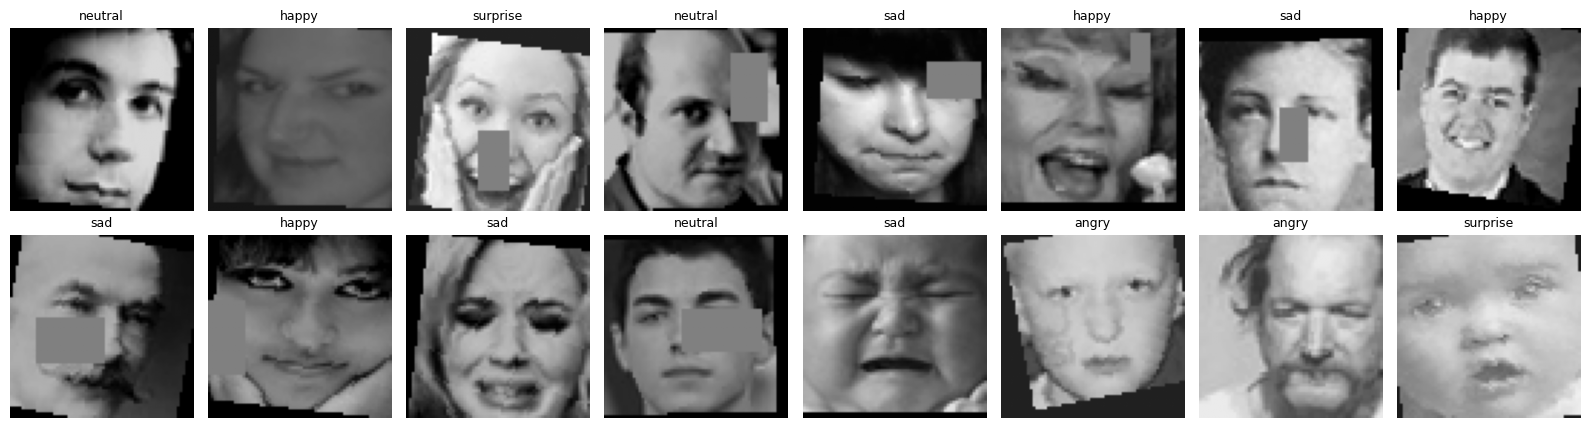

In [4]:
def load_img(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('L').resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BICUBIC))

class CachedDataset(Dataset):
    def __init__(self, df, transform, desc=''):
        paths = df['path'].tolist()
        with ThreadPoolExecutor(8) as ex:
            imgs = list(tqdm(ex.map(load_img, paths), total=len(paths), desc=desc, leave=False))
        self.imgs = np.stack(imgs)
        self.labels = df['label'].values
        self.transform = transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.imgs[i])), int(self.labels[i])

train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),
])

train_ds = CachedDataset(train_df, train_tf, 'cache train')
val_ds   = CachedDataset(val_df,   eval_tf,  'cache val')
test_ds  = CachedDataset(test_df,  eval_tf,  'cache test')

pin = device.type == 'cuda'
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=pin, drop_last=True, persistent_workers=(NUM_WORKERS > 0))
val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

xb, yb = next(iter(train_loader))
print('Batch:', tuple(xb.shape), tuple(yb.shape), '| steps/epoch:', len(train_loader))
assert xb.shape[1:] == (1, IMG_SIZE, IMG_SIZE)

fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, img, lab in zip(axs.ravel(), xb[:16], yb[:16]):
    ax.imshow(img[0].numpy() * 0.5 + 0.5, cmap='gray', vmin=0, vmax=1)
    ax.set_title(CLASSES[int(lab)], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()


## 3. Kiến trúc CNN

`Stem Conv3×3(24) → 4 stage × 2 ResBlock (stride 2 ở block đầu) → Global Avg Pool → Dropout → Linear(7)`

ResBlock = `Conv-BN-ReLU → Dropout2d → Conv-BN → SE → + shortcut → ReLU`. Dropout2d tăng dần theo độ sâu.

In [5]:
class SE(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        h = max(c // r, 8)
        self.fc1 = nn.Conv2d(c, h, 1)
        self.fc2 = nn.Conv2d(h, c, 1)
    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s), inplace=True)))


class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, drop=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.se    = SE(cout)
        self.drop  = nn.Dropout2d(drop) if drop > 0 else nn.Identity()
        self.short = None
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        identity = x if self.short is None else self.short(x)
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.drop(out)
        out = self.se(self.bn2(self.conv2(out)))
        return F.relu(out + identity, inplace=True)


class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7, stem=24, widths=(32, 48, 88, 136), drop2d=0.03, drop_fc=0.2):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem), nn.ReLU(inplace=True))
        layers, cin = [], stem
        for i, w in enumerate(widths):
            d = drop2d * (i + 1)
            layers += [ResBlock(cin, w, stride=2, drop=d), ResBlock(w, w, stride=1, drop=d)]
            cin = w
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop_fc), nn.Linear(cin, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


model = EmotionCNN(NUM_CLASSES).to(device).to(memory_format=torch.channels_last)
n_params0 = sum(p.numel() for p in model.parameters())
print(f'Params: {n_params0:,} ({n_params0/1e6:.2f}M)')
assert 0.9e6 <= n_params0 <= 1.1e6, 'Model lệch xa mục tiêu ~1M tham số'
with torch.no_grad():
    assert model.eval()(torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=device)).shape == (2, NUM_CLASSES)


Params: 1,003,935 (1.00M)


## 4. Loss, optimizer, EMA, CutMix, train/eval

In [6]:
counts  = np.bincount(train_df['label'].values, minlength=NUM_CLASSES)
weights = (counts.sum() / (NUM_CLASSES * counts)) ** 0.5
weights = torch.tensor(weights, dtype=torch.float32, device=device)
print('Class weights:', dict(zip(CLASSES, weights.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=LABEL_SMOOTHING)

# Weight decay chỉ áp cho trọng số conv/linear (ndim > 1), không cho bias/BN
decay    = [p for p in model.parameters() if p.ndim > 1]
no_decay = [p for p in model.parameters() if p.ndim <= 1]
optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': WEIGHT_DECAY},
                               {'params': no_decay, 'weight_decay': 0.0}], lr=LR)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=0.15)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)


class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else:
                v.copy_(msd[k])
ema = ModelEMA(model, EMA_DECAY)


def cutmix(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.shape[2:]
    r = np.sqrt(1 - lam)
    ch, cw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = int(np.clip(cy - ch // 2, 0, H)), int(np.clip(cy + ch // 2, 0, H))
    x1, x2 = int(np.clip(cx - cw // 2, 0, W)), int(np.clip(cx + cw // 2, 0, W))
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, y, y[idx], lam


def to_dev(x, y):
    return (x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last),
            y.to(device, non_blocking=True))


def train_one_epoch(model, loader, mix_on):
    model.train()
    total_loss, correct, n = 0.0, 0.0, 0
    for x, y in tqdm(loader, leave=False, desc='train'):
        x, y = to_dev(x, y)
        use_mix = mix_on and np.random.rand() < CUTMIX_PROB
        if use_mix:
            x, ya, yb, lam = cutmix(x, y)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
            if use_mix:
                loss = lam * criterion(out.float(), ya) + (1 - lam) * criterion(out.float(), yb)
            else:
                loss = criterion(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scale_before = scaler.get_scale()
        scaler.step(optimizer); scaler.update()
        if scaler.get_scale() >= scale_before:       # chỉ step LR khi optimizer thực sự step (AMP có thể bỏ qua bước)
            scheduler.step()
        ema.update(model)

        pred = out.argmax(1)
        c = (lam * (pred == ya).float().sum() + (1 - lam) * (pred == yb).float().sum()) if use_mix \
            else (pred == y).float().sum()
        total_loss += loss.item() * x.size(0); correct += c.item(); n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in tqdm(loader, leave=False, desc='eval'):
        x, y = to_dev(x, y)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
        loss = criterion(out.float(), y)
        total_loss += loss.item() * x.size(0)
        preds = out.argmax(1)
        correct += (preds == y).sum().item(); n += x.size(0)
        all_preds.append(preds.cpu()); all_labels.append(y.cpu())
    return (total_loss / n, correct / n, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy())


Class weights: {'angry': np.float32(1.14), 'disgust': np.float32(2.19), 'fear': np.float32(1.19), 'happy': np.float32(0.69), 'neutral': np.float32(0.88), 'sad': np.float32(0.93), 'surprise': np.float32(1.15)}


## 5. Huấn luyện

Đánh giá bằng trọng số **EMA**; checkpoint tốt nhất theo accuracy trên phần **FER** của validation.

In [7]:
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_fer_acc': [], 'val_fer_f1': []}
fer_mask = (val_df['source'].values == 'fer')
best_fer_acc, best_epoch, bad_epochs = 0.0, 0, 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    mix_on = epoch <= EPOCHS - CUTMIX_OFF_LAST
    tr_loss, tr_acc = train_one_epoch(model, train_loader, mix_on)
    va_loss, va_acc, vp, vl = evaluate(ema.module, val_loader)
    fer_acc = float((vp[fer_mask] == vl[fer_mask]).mean())
    fer_f1  = float(f1_score(vl[fer_mask], vp[fer_mask], average='macro', zero_division=0))

    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc, fer_acc, fer_f1]):
        history[k].append(v)

    flag = ''
    if fer_acc > best_fer_acc:
        best_fer_acc, best_epoch, bad_epochs = fer_acc, epoch, 0
        torch.save({'model_state_dict': ema.module.state_dict(), 'classes': CLASSES,
                    'img_size': IMG_SIZE, 'epoch': epoch, 'val_fer_acc': best_fer_acc}, BEST_PATH)
        flag = '  <-- best'
    else:
        bad_epochs += 1

    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
          f'val(EMA) loss {va_loss:.4f} acc {va_acc:.4f} | val-FER acc {fer_acc:.4f} F1 {fer_f1:.4f} | '
          f'{time.time()-t0:.0f}s{flag}')

    if bad_epochs >= PATIENCE:
        print(f'Early stopping tại epoch {epoch}. Best epoch {best_epoch} (val-FER {best_fer_acc:.4f})')
        break

pd.DataFrame(history).to_csv(OUT_DIR / 'history.csv', index=False)


train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 01/60 | train loss 1.9411 acc 0.2439 | val(EMA) loss 1.8958 acc 0.3126 | val-FER acc 0.2692 F1 0.1309 | 27s  <-- best


train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 02/60 | train loss 1.9107 acc 0.2820 | val(EMA) loss 1.8265 acc 0.3653 | val-FER acc 0.3191 F1 0.2190 | 17s  <-- best


... (170 outputs left out)

Epoch 59/60 | train loss 0.9121 acc 0.7519 | val(EMA) loss 0.9780 acc 0.7305 | val-FER acc 0.6719 F1 0.6438 | 16s


train:   0%|          | 0/309 [00:00<?, ?it/s]

eval:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 60/60 | train loss 0.9099 acc 0.7506 | val(EMA) loss 0.9783 acc 0.7305 | val-FER acc 0.6715 F1 0.6435 | 16s


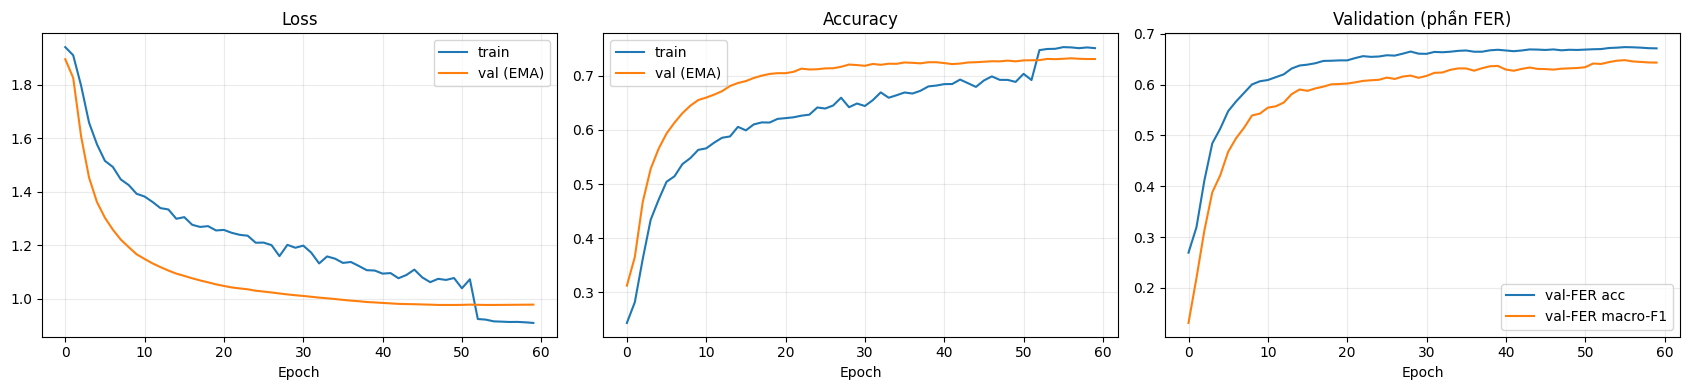

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
axs[0].plot(history['train_loss'], label='train'); axs[0].plot(history['val_loss'], label='val (EMA)'); axs[0].set_title('Loss')
axs[1].plot(history['train_acc'], label='train');  axs[1].plot(history['val_acc'], label='val (EMA)');  axs[1].set_title('Accuracy')
axs[2].plot(history['val_fer_acc'], label='val-FER acc'); axs[2].plot(history['val_fer_f1'], label='val-FER macro-F1'); axs[2].set_title('Validation (phần FER)')
for ax in axs:
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / 'training_curves.png', dpi=160); plt.show()


## 6. Đánh giá cuối trên FER-2013 test

Có/không dùng flip-TTA được quyết định bằng validation-FER, không nhìn test.

Nạp checkpoint epoch 56 (val-FER acc 0.6740)
Val-FER acc: không TTA 0.6740 | flip-TTA 0.6827  ->  dùng TTA = True
Test FER-2013 | không TTA: 0.6750 | flip-TTA: 0.6843

BÁO CÁO CHÍNH (TTA=True) | accuracy 0.6843 | macro-F1 0.6600

              precision    recall  f1-score   support

       angry     0.5988    0.6482    0.6226       958
     disgust     0.6140    0.6306    0.6222       111
        fear     0.5341    0.4668    0.4982      1024
       happy     0.8952    0.8766    0.8858      1774
     neutral     0.6166    0.6926    0.6524      1233
         sad     0.5937    0.5285    0.5592      1247
    surprise     0.7500    0.8123    0.7799       831

    accuracy                         0.6843      7178
   macro avg     0.6575    0.6651    0.6600      7178
weighted avg     0.6827    0.6843    0.6822      7178



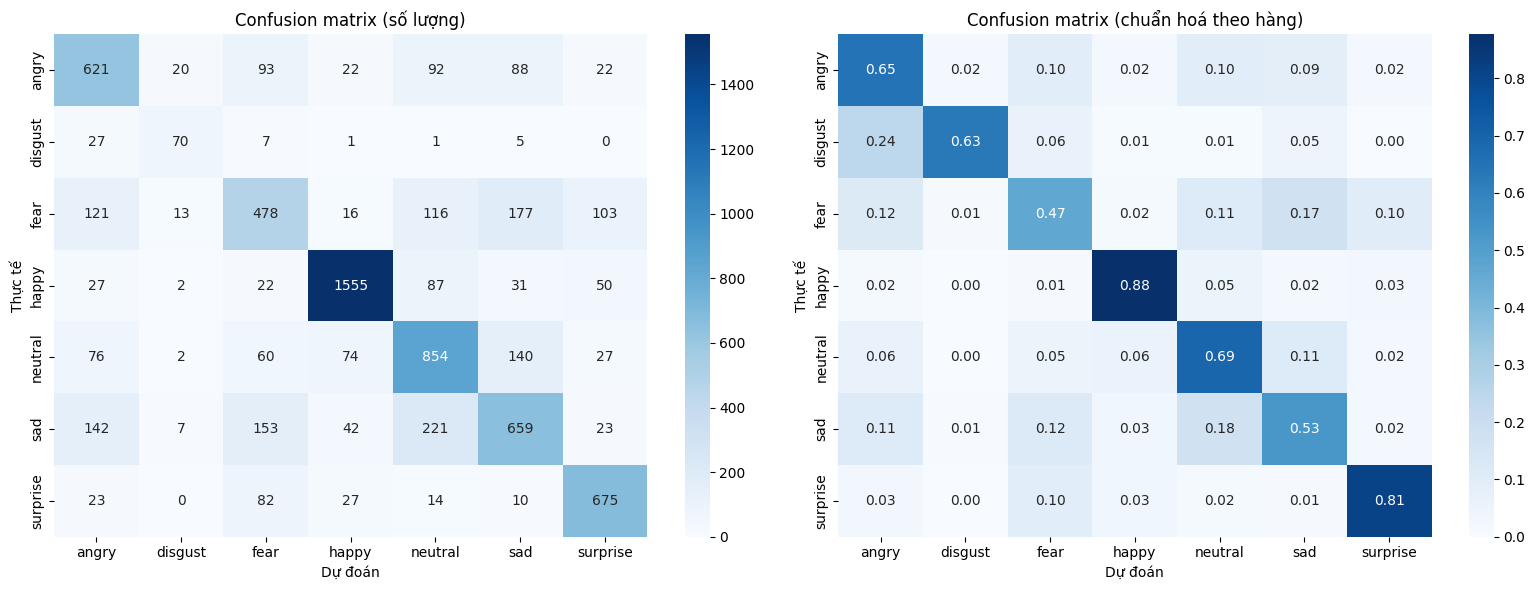

In [9]:
best_model = EmotionCNN(NUM_CLASSES).to(device).to(memory_format=torch.channels_last)
ckpt = torch.load(BEST_PATH, map_location=device)
best_model.load_state_dict(ckpt['model_state_dict']); best_model.eval()
print(f"Nạp checkpoint epoch {ckpt['epoch']} (val-FER acc {ckpt['val_fer_acc']:.4f})")

@torch.no_grad()
def predict_proba_tta(model, loader, tta=True):
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            p = torch.softmax(model(x).float(), 1)
            if tta:
                p = (p + torch.softmax(model(torch.flip(x, dims=[3])).float(), 1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

# Quyết định TTA bằng validation (phần FER)
vlabels = val_df['label'].values
v_plain = (predict_proba_tta(best_model, val_loader, False).argmax(1) == vlabels)[fer_mask].mean()
v_tta   = (predict_proba_tta(best_model, val_loader, True ).argmax(1) == vlabels)[fer_mask].mean()
USE_TTA = bool(v_tta > v_plain)
print(f'Val-FER acc: không TTA {v_plain:.4f} | flip-TTA {v_tta:.4f}  ->  dùng TTA = {USE_TTA}')

# Test (FER-2013): báo cả hai để so sánh, nhưng báo cáo chính theo lựa chọn từ validation
labels = test_df['label'].values
probs_plain = predict_proba_tta(best_model, test_loader, False)
probs_tta   = predict_proba_tta(best_model, test_loader, True)
print(f'Test FER-2013 | không TTA: {(probs_plain.argmax(1)==labels).mean():.4f} | flip-TTA: {(probs_tta.argmax(1)==labels).mean():.4f}')

probs = probs_tta if USE_TTA else probs_plain
preds = probs.argmax(1)
test_acc = float((preds == labels).mean())
test_f1  = float(f1_score(labels, preds, average='macro'))
print(f'\nBÁO CÁO CHÍNH (TTA={USE_TTA}) | accuracy {test_acc:.4f} | macro-F1 {test_f1:.4f}\n')
print(classification_report(labels, preds, target_names=CLASSES, digits=4))

cm = confusion_matrix(labels, preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[0])
axs[0].set_title('Confusion matrix (số lượng)')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[1])
axs[1].set_title('Confusion matrix (chuẩn hoá theo hàng)')
for ax in axs:
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
plt.tight_layout(); plt.savefig(OUT_DIR / 'test_confusion_matrix.png', dpi=160); plt.show()

model = best_model


## 7. Tốc độ và kích thước

In [10]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

@torch.no_grad()
def benchmark(net, dev, batch_size, n_iter=200, warmup=30, amp=False):
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=dev)
    with torch.autocast(device_type=dev.type, enabled=(amp and dev.type == 'cuda')):
        for _ in range(warmup):
            net(x)
        if dev.type == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            net(x)
        if dev.type == 'cuda': torch.cuda.synchronize()
        dt = time.perf_counter() - t0
    return batch_size * n_iter / dt, dt / n_iter * 1000

rows = []
if device.type == 'cuda':
    for bs in [1, 32, 128, 512]:
        for amp in [False, True]:
            fps, ms = benchmark(model, device, bs, amp=amp)
            rows.append({'device': torch.cuda.get_device_name(0), 'batch_size': bs,
                         'precision': 'FP16 (AMP)' if amp else 'FP32', 'FPS': round(fps, 1), 'ms / batch': round(ms, 2)})
cpu_model = copy.deepcopy(model).cpu().eval()
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
for bs in [1, 32]:
    fps, ms = benchmark(cpu_model, torch.device('cpu'), bs, n_iter=150 if bs == 1 else 40, warmup=10)
    rows.append({'device': 'CPU', 'batch_size': bs, 'precision': 'FP32', 'FPS': round(fps, 1), 'ms / batch': round(ms, 2)})
fps_df = pd.DataFrame(rows); fps_df.to_csv(OUT_DIR / 'speed.csv', index=False)
display(fps_df)
del cpu_model

@torch.no_grad()
def benchmark_e2e(paths, warmup=20):
    for p in paths[:warmup]:
        model(eval_tf(Image.open(p).convert('L')).unsqueeze(0).to(device))
    sync()
    t0 = time.perf_counter()
    for p in paths:
        x = eval_tf(Image.open(p).convert('L')).unsqueeze(0).to(device)
        model(x).argmax(1).item()
    sync()
    return len(paths) / (time.perf_counter() - t0)

e2e_fps = benchmark_e2e(test_df['path'].sample(500, random_state=SEED).tolist())
print(f'End-to-end (batch=1, gồm đọc ảnh + tiền xử lý): {e2e_fps:.1f} FPS (~{1000/e2e_fps:.2f} ms/ảnh)')

n_params = sum(p.numel() for p in model.parameters())
size_mb = os.path.getsize(BEST_PATH) / 1024**2
print(f'Params: {n_params/1e6:.2f}M | Kích thước file: {size_mb:.1f} MB')


,device,batch_size,precision,FPS,ms / batch
0,Tesla T4,1,FP32,247.4,4.04
1,Tesla T4,1,FP16 (AMP),252.2,3.97
2,Tesla T4,32,FP32,7993.0,4.00
3,Tesla T4,32,FP16 (AMP),8033.0,3.98
4,Tesla T4,128,FP32,10353.4,12.36
5,Tesla T4,128,FP16 (AMP),26250.8,4.88
6,Tesla T4,512,FP32,10152.5,50.43
7,Tesla T4,512,FP16 (AMP),26729.2,19.16
8,CPU,1,FP32,153.2,6.53
9,CPU,32,FP32,557.6,57.39


End-to-end (batch=1, gồm đọc ảnh + tiền xử lý): 84.4 FPS (~11.85 ms/ảnh)
Params: 1.00M | Kích thước file: 3.9 MB


## 8. Phân tích lỗi

Số ảnh dự đoán sai: 2266 / 7178 (31.57%)


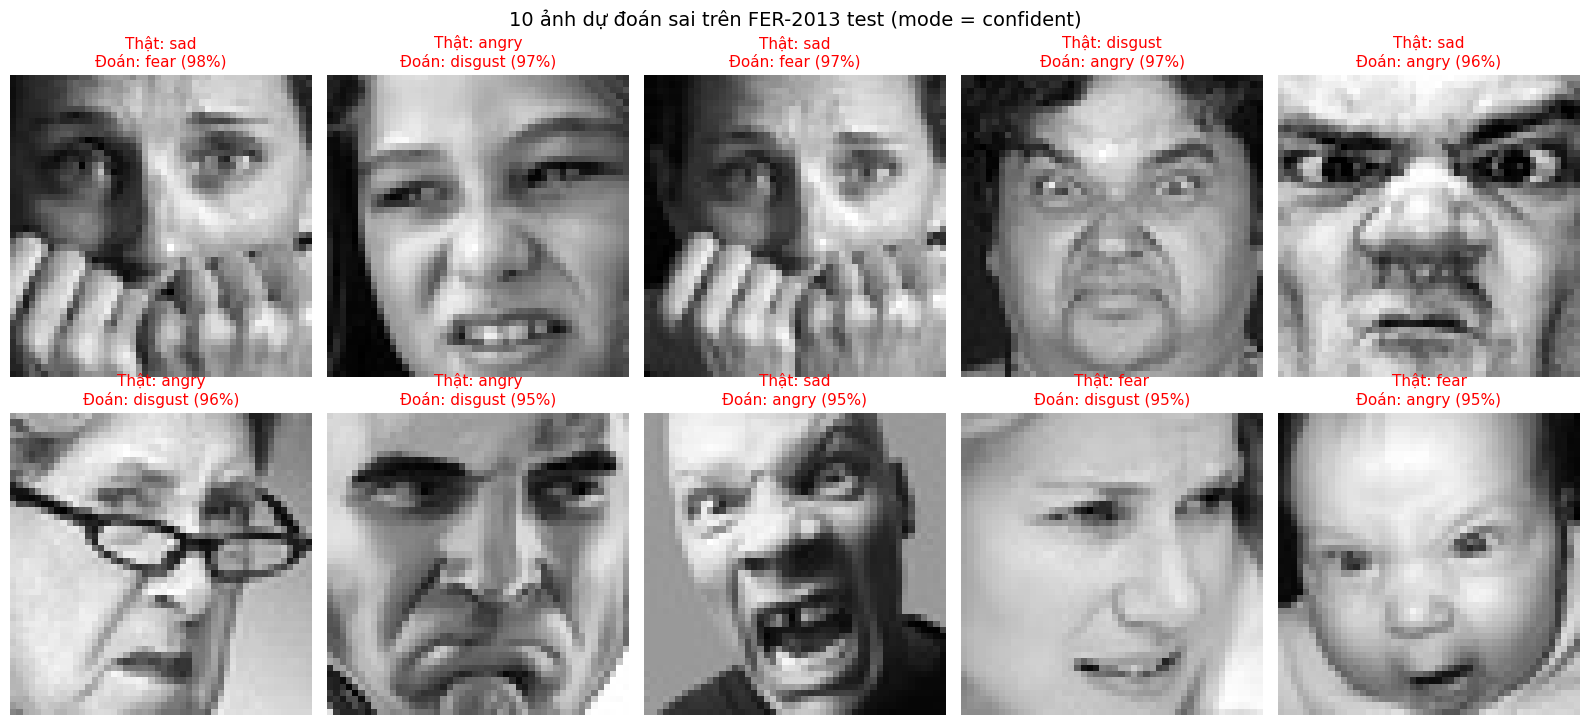

,path,thật,đoán,độ tin cậy
0,PublicTest_31266486.jpg,sad,fear,98.0%
1,PublicTest_57865005.jpg,angry,disgust,96.8%
2,PrivateTest_57288449.jpg,sad,fear,96.7%
3,PrivateTest_3881740.jpg,disgust,angry,96.6%
4,PublicTest_40104653.jpg,sad,angry,96.5%
5,PrivateTest_66928656.jpg,angry,disgust,95.6%
6,PublicTest_55079248.jpg,angry,disgust,95.3%
7,PublicTest_43383329.jpg,sad,angry,95.2%
8,PrivateTest_65117768.jpg,fear,disgust,95.1%
9,PublicTest_97108933.jpg,fear,angry,94.8%


{
  "datasets": [
    "fer2013",
    "raf-db"
  ],
  "img_size": 64,
  "best_epoch": 56,
  "val_fer_acc": 0.6739811912225705,
  "flip_tta_used": true,
  "fer2013_test": {
    "accuracy": 0.68431317915854,
    "macro_f1": 0.6600328725253347
  },
  "parameters": 1003935,
  "classes": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
  ]
}


In [11]:
MODE = 'confident'     # 'confident' = sai mà tự tin nhất | 'random' = ngẫu nhiên
N_SHOW = 10

conf = probs.max(1)
wrong_idx = np.where(preds != labels)[0]
print(f'Số ảnh dự đoán sai: {len(wrong_idx)} / {len(labels)} ({len(wrong_idx)/len(labels)*100:.2f}%)')

if MODE == 'confident':
    chosen = wrong_idx[np.argsort(-conf[wrong_idx])[:N_SHOW]]
else:
    chosen = np.random.RandomState(SEED).choice(wrong_idx, N_SHOW, replace=False)

fig, axs = plt.subplots(2, 5, figsize=(16, 7.5))
for ax, i in zip(axs.ravel(), chosen):
    with Image.open(test_df.loc[i, 'path']) as im:
        ax.imshow(im.convert('L'), cmap='gray')
    ax.set_title(f'Thật: {CLASSES[labels[i]]}\nĐoán: {CLASSES[preds[i]]} ({conf[i]*100:.0f}%)', color='red', fontsize=11)
    ax.axis('off')
plt.suptitle(f'{N_SHOW} ảnh dự đoán sai trên FER-2013 test (mode = {MODE})', fontsize=14)
plt.tight_layout(); plt.savefig(OUT_DIR / 'test_errors.png', dpi=160); plt.show()

display(pd.DataFrame({
    'path': [Path(test_df.loc[i, 'path']).name for i in chosen],
    'thật': [CLASSES[labels[i]] for i in chosen],
    'đoán': [CLASSES[preds[i]] for i in chosen],
    'độ tin cậy': [f'{conf[i]*100:.1f}%' for i in chosen],
}))

summary = {'datasets': ['fer2013', 'raf-db'], 'img_size': IMG_SIZE, 'best_epoch': int(best_epoch),
           'val_fer_acc': float(best_fer_acc), 'flip_tta_used': USE_TTA,
           'fer2013_test': {'accuracy': test_acc, 'macro_f1': test_f1},
           'parameters': int(n_params), 'classes': CLASSES}
with open(OUT_DIR / 'summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))
